# Plot MCWF squeezing analysis

Load all globally analyzed trajectory ensembles and overlay their group-resolved moments and squeezing.

In [5]:
from pathlib import Path
import sys


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "common").is_dir() and (candidate / "slurm").is_dir():
            return candidate
    raise RuntimeError("Could not find repo root containing common/ and slurm/.")


repo_root = find_repo_root(Path.cwd().resolve())
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from common.plotting import plot_bloch_angles, plot_spin_components, plot_squeezing
from slurm.j_moments_io import load_j_moments_artifact

In [6]:
input_dir = repo_root / "slurm" / "output"

filenames = []
for omega_1 in (1.0, 0.9, 0.8, 0.7):
    filenames.append(f"v2_omega_{omega_1:.1f}.pkl")

artifact_paths = tuple(input_dir / filename for filename in filenames)
missing_paths = tuple(path for path in artifact_paths if not path.is_file())
if missing_paths:
    raise FileNotFoundError(f"Missing analyzed squeezing files: {missing_paths}")

In [7]:
moments_by_omega_1 = []
for artifact_path in artifact_paths:
    artifact = load_j_moments_artifact(artifact_path)
    moments = artifact["moments"]
    if moments.metadata is None or moments.J is None or moments.squeezing is None:
        raise ValueError(f"{artifact_path} does not contain complete squeezing moments.")
    if not moments.metadata.omega_i:
        raise ValueError(f"{artifact_path} does not contain a supplied group coupling.")
    moments_by_omega_1.append((moments.metadata.omega_i[0], moments))

moments_by_omega_1.sort(key=lambda item: item[0], reverse=True)
phase_protocol = moments_by_omega_1[0][1].metadata.phase_protocol
if any(
    moments.metadata.phase_protocol != phase_protocol
    for _, moments in moments_by_omega_1[1:]
):
    raise ValueError("All squeezing files must share the same phase protocol.")

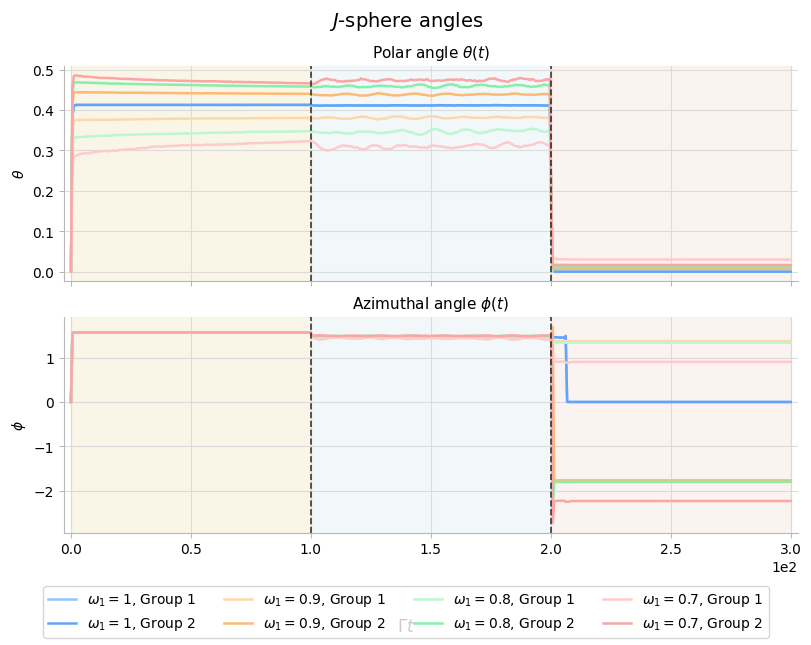

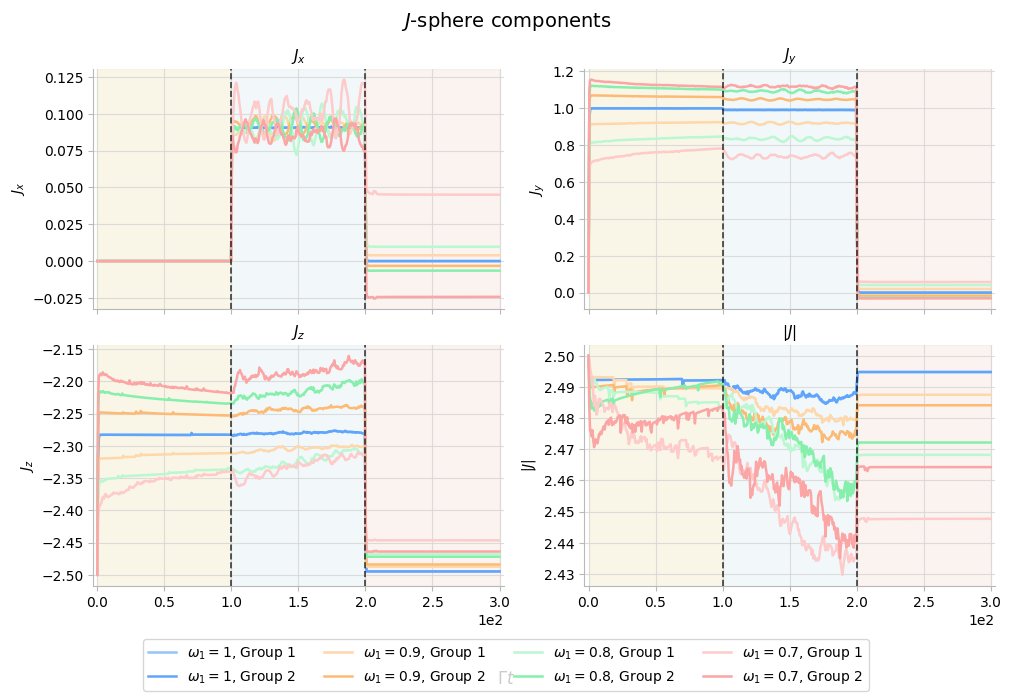

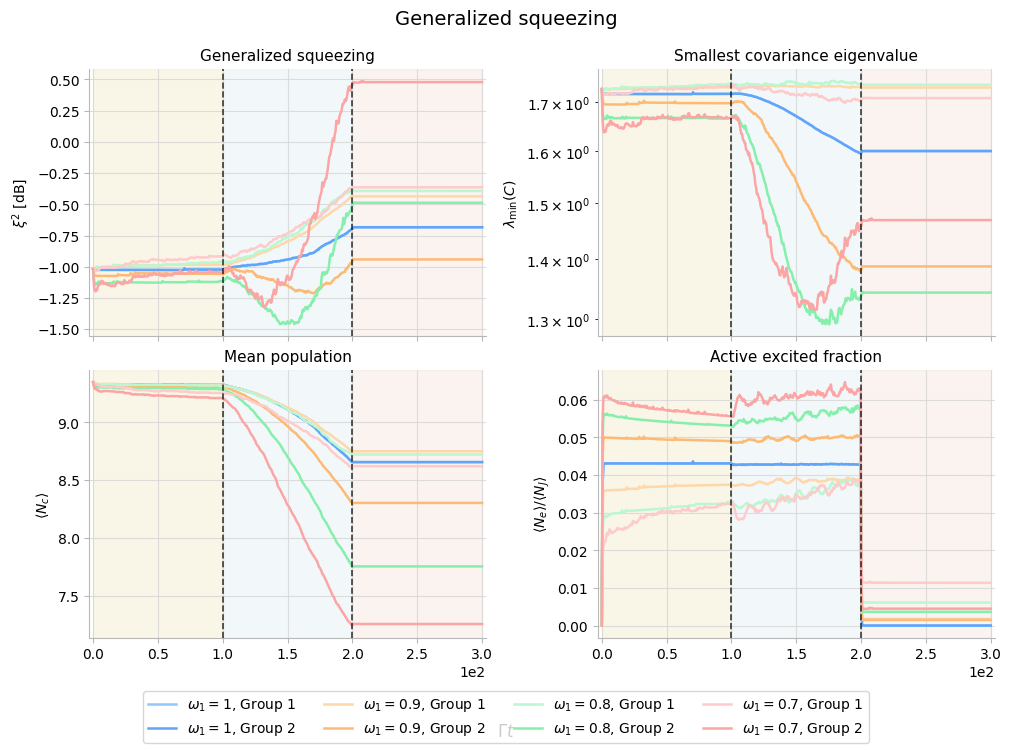

In [8]:
angle_axes = None
component_axes = None
squeezing_axes = None

for colour_family_index, (omega_1, moments) in enumerate(moments_by_omega_1):
    group_labels = tuple(
        rf"$\omega_1={omega_1:g}$, Group {group_index + 1}"
        for group_index in range(len(moments.squeezing))
    )

    angle_fig, angle_axes = plot_bloch_angles(
        moments.t,
        moments.J.theta,
        moments.J.phi,
        labels=group_labels,
        colour_family_index=colour_family_index,
        axes=angle_axes,
        phase_protocol=phase_protocol,
        title=rf"$J$-sphere angles",
    )

    component_fig, component_axes = plot_spin_components(
        moments.t,
        moments.J.x,
        moments.J.y,
        moments.J.z,
        moments.J.length,
        labels=group_labels,
        colour_family_index=colour_family_index,
        axes=component_axes,
        phase_protocol=phase_protocol,
        title=rf"$J$-sphere components",
    )

    squeezing_fig, squeezing_axes = plot_squeezing(
        moments.t,
        tuple(series.xi2 for series in moments.squeezing),
        tuple(series.lambda_min for series in moments.squeezing),
        tuple(series.N_c for series in moments.squeezing),
        tuple(series.excited_fraction_active for series in moments.squeezing),
        labels=group_labels,
        colour_family_index=colour_family_index,
        axes=squeezing_axes,
        phase_protocol=phase_protocol,
        title="Generalized squeezing",
    )